<a href="https://colab.research.google.com/github/danielshikuku/Hypertension-Risk-Analytics/blob/main/hypertension.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Reflection: Hypertension Risk Analytics and Decision-Support Application**

**Task 1: Research motivation**

Hypertension is a major public health concern because its development is influenced by a combination of demographic, behavioral and clinical factors. Awareness of the relationship between these factors and hypertension can be useful in identifying trends that warrant consideration in primary health care and in health education and prevention. This project consequently analyzes the available data to investigate disparities in hypertension among population groups and to investigate potential associations between lifestyle habits, body measurements, family history and clinical indicators. Rather than assuming that individual factors directly cause hypertension, the analysis seeks to establish what associations and patterns are evident in the data and where further investigation may be needed.Four questions guided the initial analysis:

1. How do age and gender relate to hypertension prevalence?
2. How are salt intake, physical activity, smoking, stress and alcohol consumption associated with hypertension?
3. What relationships exist between BMI and waist circumference and hypertension?
4. How are family history, creatinine, fasting glucose and cholesterol associated with hypertension? They cover demographic, behavioural, anthropometric and clinical factors while allowing unexpected patterns to emerge.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

1st I cloned my hypertension risk analysis to github to enable me commit changes with much ease and  then loaded my Dataset and finally ran a few codes to know the general information for better understanding.

In [ ]:

username = "danielshikuku"
repo = "Hypertension-Risk-Analytics"

!git clone https://github.com/{username}/{repo}.git
%cd {repo}
%ls

Cloning into 'Hypertension-Risk-Analytics'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (94/94), done.
remote: Compressing objects: 100% (94/94), done.
remote: Total 94 (delta 50), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (94/94), 599.20 KiB | 2.62 MiB/s, done.
Resolving deltas: 100% (50/50), done.
/content/Hypertension-Risk-Analytics
cleaned_hypertension_dataset_5000.csv  hypertension.ipynb
hypertension_dataset_5000.csv


In [ ]:
df = pd.read_csv("hypertension_dataset_5000.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     5000 non-null   float64
 1   Gender                  5000 non-null   object 
 2   BMI                     5000 non-null   float64
 3   Waist_Circumference_cm  4846 non-null   float64
 4   Salt_Intake             4939 non-null   object 
 5   Physical_Activity       5000 non-null   object 
 6   Alcohol_Consumption     3632 non-null   object 
 7   Smoking_Status          5000 non-null   object 
 8   Stress_Level            4909 non-null   object 
 9   Sleep_Hours             4837 non-null   float64
 10  Family_History_HTN      5000 non-null   object 
 11  Creatinine_mg_dL        4867 non-null   float64
 12  Fasting_Glucose_mg_dL   4821 non-null   float64
 13  Cholesterol_mg_dL       4841 non-null   float64
 14  Systolic_BP_mmHg        5000 non-null   

In [ ]:
df.head()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
0,83.2,Male,24.6,92.5,Normal,Light,NaN,Former,Moderate,7.5,No,0.98,89.0,201.4,119,65,Normal,No
1,69.0,Female,26.1,76.6,Very High,Light,NaN,Former,Low,6.5,Yes,NaN,83.2,178.9,132,81,Stage 1 Hypertension,Yes
2,45.1,Male,24.5,86.4,High,Sedentary,Occasional,Former,Very High,6.1,No,1.02,86.0,163.2,131,87,Stage 1 Hypertension,Yes
3,45.5,Male,25.6,85.2,Normal,Active,Moderate,Current,High,6.4,Yes,0.86,80.5,146.0,127,88,Stage 1 Hypertension,Yes
4,41.7,Male,28.7,97.4,High,Active,Moderate,Current,High,6.9,No,1.27,97.0,210.6,120,78,Elevated,No


In [ ]:
df.tail()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
4995,33.2,Male,26.4,82.6,Normal,Light,Heavy,Never,High,7.8,No,0.96,78.9,230.6,125,87,Stage 1 Hypertension,Yes
4996,40.0,Male,26.4,84.0,Low,Light,NaN,Former,Moderate,8.2,Yes,NaN,108.7,175.9,131,73,Stage 1 Hypertension,Yes
4997,38.5,Female,35.1,NaN,High,Sedentary,Occasional,Former,Moderate,6.5,Yes,0.74,83.7,178.3,141,86,Stage 2 Hypertension,Yes
4998,26.2,Female,25.4,71.9,High,Sedentary,Occasional,Current,Very High,7.4,Yes,0.72,127.9,NaN,129,74,Elevated,No
4999,20.9,Female,16.3,56.7,Very High,Active,NaN,Never,Moderate,7.4,Yes,0.78,NaN,152.4,97,63,Normal,No


In [ ]:
df.shape

(5000, 18)

In [ ]:
df.describe(include="all")

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
count,5000.000000,5000,5000.000000,4846.000000,4939,5000,3632,5000,4909,4837.000000,5000,4867.000000,4821.000000,4841.000000,5000.000000,5000.000000,5000,5000
unique,NaN,2,NaN,NaN,4,4,3,3,4,NaN,2,NaN,NaN,NaN,NaN,NaN,4,2
top,NaN,Female,NaN,NaN,Normal,Light,Occasional,Never,Moderate,NaN,No,NaN,NaN,NaN,NaN,NaN,Normal,No
freq,NaN,2581,NaN,NaN,1696,1678,1910,2805,1844,NaN,3218,NaN,NaN,NaN,NaN,NaN,2713,3250
mean,48.648320,NaN,27.876320,89.417623,NaN,NaN,NaN,NaN,NaN,6.850444,NaN,0.942063,93.301058,187.219851,116.826600,74.259600,NaN,NaN
std,16.908037,NaN,4.254628,11.410790,NaN,NaN,NaN,NaN,NaN,1.042016,NaN,0.171618,12.753358,30.546704,16.385269,9.483849,NaN,NaN
min,18.200000,NaN,16.200000,54.000000,NaN,NaN,NaN,NaN,NaN,3.500000,NaN,0.510000,62.100000,105.000000,88.000000,50.000000,NaN,NaN
25%,34.575000,NaN,24.900000,81.500000,NaN,NaN,NaN,NaN,NaN,6.200000,NaN,0.820000,84.500000,165.600000,104.000000,67.000000,NaN,NaN
50%,47.400000,NaN,27.700000,89.100000,NaN,NaN,NaN,NaN,NaN,6.900000,NaN,0.930000,92.200000,187.300000,115.000000,74.000000,NaN,NaN
75%,61.600000,NaN,30.800000,97.100000,NaN,NaN,NaN,NaN,NaN,7.500000,NaN,1.050000,100.900000,207.600000,128.000000,81.000000,NaN,NaN


In [ ]:
df.dtypes.value_counts()

,count
object,9
float64,7
int64,2


In [ ]:
df.columns

Index(['Age', 'Gender', 'BMI', 'Waist_Circumference_cm', 'Salt_Intake',
       'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status',
       'Stress_Level', 'Sleep_Hours', 'Family_History_HTN', 'Creatinine_mg_dL',
       'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg',
       'Diastolic_BP_mmHg', 'BP_Category', 'Hypertension'],
      dtype='object')

2nd I had to check missing values just to understand the scope of the raw data. The dataset contains 5,000 records and 18 variables: nine numerical and nine categorical. The variables included are: Demographic, anthropometric, lifestyle and clinical measures and the outcome is Hypertension (Yes/No).
Missing values occurred in waist circumference (154), salt intake (61), alcohol consumption (1,368), stress level (91), sleep hours (163), creatinine (133), fasting glucose (179) and cholesterol (159). No duplicate records were found. Alcohol showed the biggest difference (around 27%), which restricts comparisons of this type. Additionally, blood-pressure readings had to be carefully treated, as they had a direct link to the outcome definition.


In [ ]:
pd.DataFrame({'dtype':df.dtypes.astype(str),'unique':df.nunique(),'missing':df.isnull().sum()})


,dtype,unique,missing
Age,float64,681,0
Gender,object,2,0
BMI,float64,245,0
Waist_Circumference_cm,float64,578,154
Salt_Intake,object,4,61
Physical_Activity,object,4,0
Alcohol_Consumption,object,3,1368
Smoking_Status,object,3,0
Stress_Level,object,4,91
Sleep_Hours,float64,68,163


3rd Handle missing values from the 8 columns

For numerical variables, I used the median imputation since the median is not affected as much by extreme values as the mean is. The most common categories were “Salt intake” and “Stress.” Missing alcohol values were labelled “Unknown”, rather than assuming a consumption level. This retained records without inventing behaviour. No duplicates were removed.
I designed BMI_group, Age band, Older, Obese and High glucose to facilitate the interpretation of comparisons. These features clustered BMI and age and identified age ≥60 and BMI ≥30 with glucose ≥100 mg/dL. Pulse pressure was calculated as systolic minus diastolic pressure. Lifestyle_risk_count included five behaviours: sedentary activity, high/very high salt intake, heavy alcohol use, current smoking, and high/very high stress.

1) I started by first fixing the missing values of "alcohol_consuption"

In [ ]:
df["Alcohol_Consumption"] = df["Alcohol_Consumption"].fillna("Unknown")
print(df["Alcohol_Consumption"].isna().sum())

0


2) I continued by fixing missing value "salt_intake"

In [ ]:
df["Salt_Intake"] = df["Salt_Intake"].fillna(df["Salt_Intake"].mode()[0])
print(df["Salt_Intake"].isna().sum())

0


3) I fixed missing value "sleeping_hours"

In [ ]:
df['Sleep_Hours'] = df['Sleep_Hours'].fillna(df['Sleep_Hours'].median())
print(df["Sleep_Hours"].isna().sum())

0


4) I continued by fixing missing value "Waist_Circumference_cm"

In [ ]:
df['Waist_Circumference_cm'] = df['Waist_Circumference_cm'].fillna(df['Waist_Circumference_cm'].median())
print(df["Waist_Circumference_cm"].isna().sum())

0


5) I then fixed missing value "stress_level"

In [ ]:
df["Stress_Level"] = df["Stress_Level"].fillna(df["Stress_Level"].mode()[0])
print(df["Stress_Level"].isna().sum())

0


6) I continued by fixing missing value "Creatinine_mg_dL"


In [ ]:
df['Creatinine_mg_dL'] = df['Creatinine_mg_dL'].fillna(df['Creatinine_mg_dL'].median())
print(df['Creatinine_mg_dL'].isna().sum())

0


7) I fixed missing value "Cholesterol_mg_dL"

In [ ]:
df['Cholesterol_mg_dL'] = df['Cholesterol_mg_dL'].fillna(df['Cholesterol_mg_dL'].median())
print(df['Cholesterol_mg_dL'].isna().sum())

0


8) I finally fixed missing value "Fasting_Glucose_mg_dm"

In [ ]:
df['Fasting_Glucose_mg_dL'] = df['Fasting_Glucose_mg_dL'].fillna(df['Fasting_Glucose_mg_dL'].median())
print(df['Fasting_Glucose_mg_dL'].isna().sum())

0


I again ran the code to check any other missing value after handling

In [ ]:
pd.DataFrame({'dtype':df.dtypes.astype(str),'unique':df.nunique(),'missing':df.isnull().sum()})

,dtype,unique,missing
Age,float64,681,0
Gender,object,2,0
BMI,float64,245,0
Waist_Circumference_cm,float64,578,0
Salt_Intake,object,4,0
Physical_Activity,object,4,0
Alcohol_Consumption,object,4,0
Smoking_Status,object,3,0
Stress_Level,object,4,0
Sleep_Hours,float64,68,0


In [ ]:
print(df.isnull().sum())

Age                       0
Gender                    0
BMI                       0
Waist_Circumference_cm    0
Salt_Intake               0
Physical_Activity         0
Alcohol_Consumption       0
Smoking_Status            0
Stress_Level              0
Sleep_Hours               0
Family_History_HTN        0
Creatinine_mg_dL          0
Fasting_Glucose_mg_dL     0
Cholesterol_mg_dL         0
Systolic_BP_mmHg          0
Diastolic_BP_mmHg         0
BP_Category               0
Hypertension              0
dtype: int64


4th Removing duplicate from my dataset

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Age,float64
Gender,object
BMI,float64
Waist_Circumference_cm,float64
Salt_Intake,object
Physical_Activity,object
Alcohol_Consumption,object
Smoking_Status,object
Stress_Level,object
Sleep_Hours,float64


5th Since there was no duplicate I proceded to check category data

Identify which categories are treated as text or categories

In [ ]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("Categorical Columns:", list(categorical_cols))

Categorical Columns: ['Gender', 'Salt_Intake', 'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status', 'Stress_Level', 'Family_History_HTN', 'BP_Category', 'Hypertension']


Check unique values and search for typos in 1st 10 columns

In [ ]:
for col in categorical_cols:
    print(f"\n--- Unique values in '{col}' (Top 10) ---")
    print(df[col].value_counts(dropna=False).head(10))


--- Unique values in 'Gender' (Top 10) ---
Gender
Female    2581
Male      2419
Name: count, dtype: int64

--- Unique values in 'Salt_Intake' (Top 10) ---
Salt_Intake
Normal       1757
High         1597
Very High    1011
Low           635
Name: count, dtype: int64

--- Unique values in 'Physical_Activity' (Top 10) ---
Physical_Activity
Light        1678
Sedentary    1327
Moderate     1258
Active        737
Name: count, dtype: int64

--- Unique values in 'Alcohol_Consumption' (Top 10) ---
Alcohol_Consumption
Occasional    1910
Unknown       1368
Moderate      1231
Heavy          491
Name: count, dtype: int64

--- Unique values in 'Smoking_Status' (Top 10) ---
Smoking_Status
Never      2805
Former     1440
Current     755
Name: count, dtype: int64

--- Unique values in 'Stress_Level' (Top 10) ---
Stress_Level
Moderate     1935
High         1410
Low           844
Very High     811
Name: count, dtype: int64

--- Unique values in 'Family_History_HTN' (Top 10) ---
Family_History_HTN
No     

Check for structural anomalies

In [ ]:
for col in categorical_cols:
    has_whitespace = df[col].astype(str).str.contains(r'^\s|\s$').any()
    has_mixed_case = df[col].dropna().nunique() != df[col].dropna().str.lower().nunique()
    if has_whitespace or has_mixed_case:
        print(f"Column '{col}' needs cleaning (Whitespace: {has_whitespace}, Mixed Case: {has_mixed_case})")

Check cardinality (High cardinality text columns shouldn't be cast as 'category')

In [ ]:
print("\n--- Cardinality Check ---")
print(df[categorical_cols].nunique())


--- Cardinality Check ---
Gender                 2
Salt_Intake            4
Physical_Activity      4
Alcohol_Consumption    4
Smoking_Status         3
Stress_Level           4
Family_History_HTN     2
BP_Category            4
Hypertension           2
dtype: int64


In [ ]:
print(df.columns.tolist())

['Age', 'Gender', 'BMI', 'Waist_Circumference_cm', 'Salt_Intake', 'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status', 'Stress_Level', 'Sleep_Hours', 'Family_History_HTN', 'Creatinine_mg_dL', 'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg', 'Diastolic_BP_mmHg', 'BP_Category', 'Hypertension']


6th Checked for outliers and invalid values

 checking using loops

In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

Age : 0 outliers
BMI : 23 outliers
Waist_Circumference_cm : 33 outliers
Sleep_Hours : 57 outliers
Creatinine_mg_dL : 39 outliers
Fasting_Glucose_mg_dL : 94 outliers
Cholesterol_mg_dL : 21 outliers
Systolic_BP_mmHg : 22 outliers
Diastolic_BP_mmHg : 11 outliers


A boxplot helps you visually identify outliers

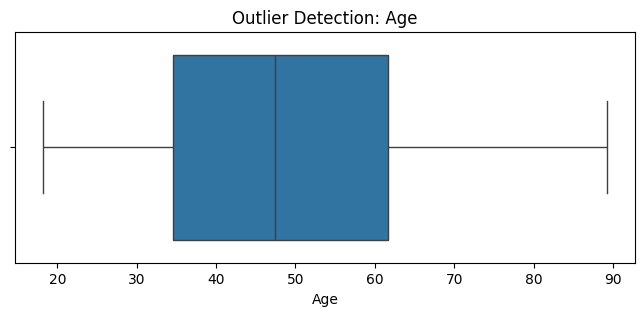

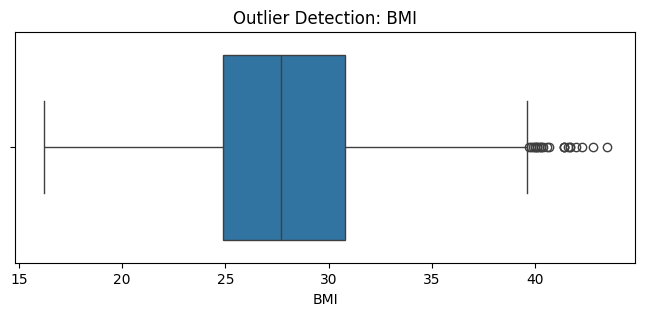

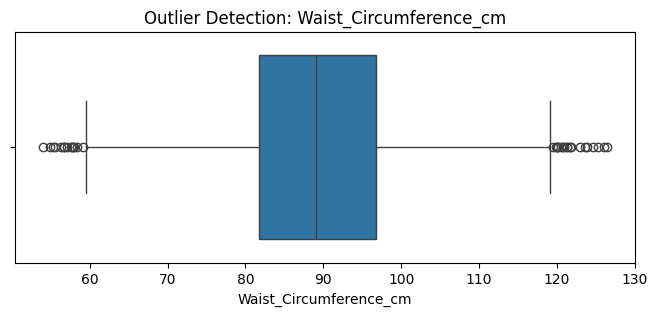

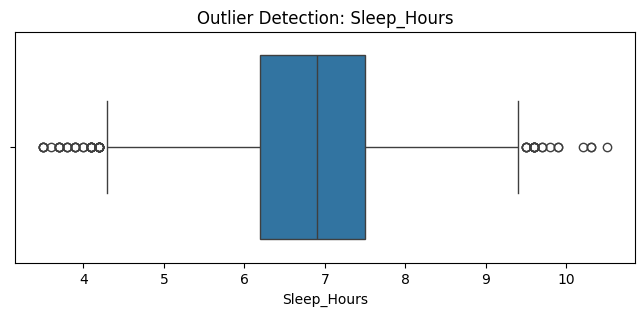

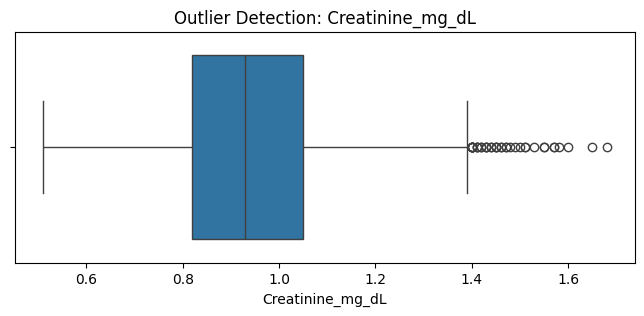

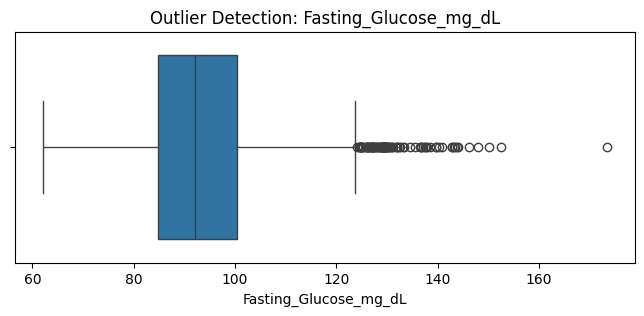

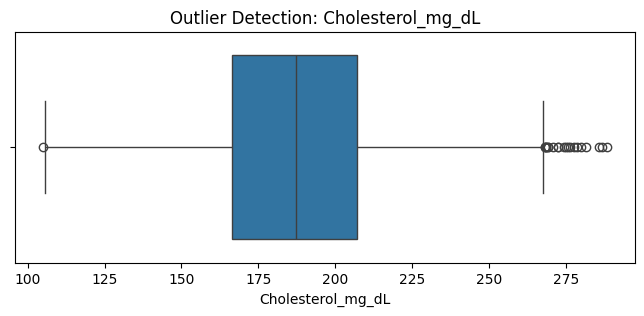

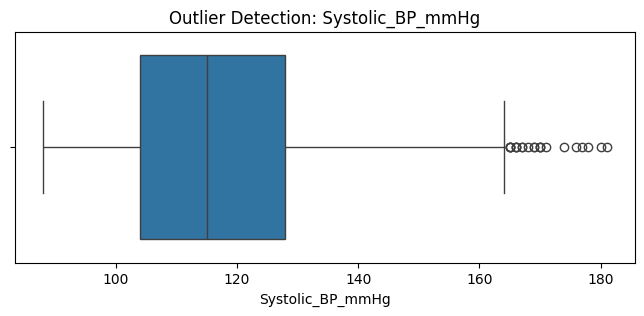

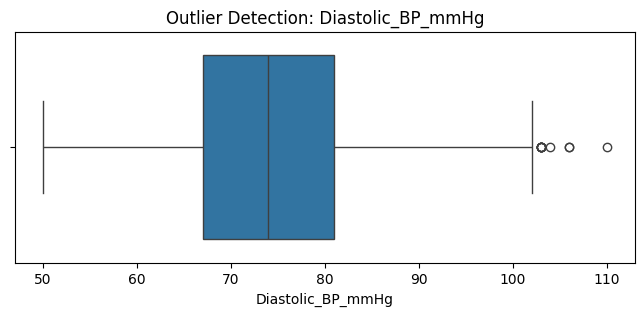

In [ ]:
numeric_columns = [
    "Age",
    "BMI",
    "Waist_Circumference_cm",
    "Sleep_Hours",
    "Creatinine_mg_dL",
    "Fasting_Glucose_mg_dL",
    "Cholesterol_mg_dL",
    "Systolic_BP_mmHg",
    "Diastolic_BP_mmHg"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection: {col}")
    plt.show()

check for invalid value

In [ ]:
print("Invalid Age:")
display(df[df["Age"] < 0])

print("Invalid BMI:")
display(df[df["BMI"] <= 0])

print("Invalid Waist Circumference:")
display(df[df["Waist_Circumference_cm"] <= 0])

print("Invalid Glucose:")
display(df[df["Fasting_Glucose_mg_dL"] < 0])

print("Invalid Cholesterol:")
display(df[df["Cholesterol_mg_dL"] < 0])

Invalid Age:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid BMI:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Waist Circumference:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Glucose:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Cholesterol:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


7th Created a new column ie feature engineering

1st column age_band(age): 'Under 30', '30-44', '45-59', '60+'

In [ ]:
def age_band(age):
    if age < 30:
        return 'Under 30'
    elif age < 45:
        return '30-44'
    elif age < 60:
        return '45-59'
    else:
        return '60+'

df['Age_band'] = df['Age'].apply(age_band)
df['Age_band'].value_counts()

,count
Age_band,
30-44,1462
60+,1393
45-59,1339
Under 30,806


2nd column bmi_group(bmi): under 18.5 'Underweight', under 25 'Normal', under 30 'Overweight', otherwise 'Obese'.

In [ ]:
def bmi_Group(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['BMI_Group'] = df['BMI'].apply(bmi_Group)
print(df['BMI_Group'].value_counts())

BMI_Group
Overweight     2195
Obese          1542
Normal         1223
Underweight      40
Name: count, dtype: int64


3rd Blood Pressure Status

In [ ]:
def bp_status(systolic, diastolic):
    if pd.isna(systolic) or pd.isna(diastolic):
        return "Unknown"
    elif systolic >= 140 or diastolic >= 90:
        return "High"
    elif systolic >= 120 or diastolic >= 80:
        return "Elevated"
    else:
        return "Normal"

df["BP_Status"] = df.apply(lambda row: bp_status(row["Systolic_BP_mmHg"],row["Diastolic_BP_mmHg"]),axis=1)
print(df[["Systolic_BP_mmHg", "Diastolic_BP_mmHg", "BP_Status"]].head(10))
print(df["BP_Status"].value_counts())

   Systolic_BP_mmHg  Diastolic_BP_mmHg BP_Status
0               119                 65    Normal
1               132                 81  Elevated
2               131                 87  Elevated
3               127                 88  Elevated
4               120                 78  Elevated
5               112                 78    Normal
6               113                 71    Normal
7               126                 91      High
8               131                 89  Elevated
9                99                 69    Normal
BP_Status
Normal      2713
Elevated    1684
High         603
Name: count, dtype: int64


4th Sleeping status

In [ ]:

def sleep_category(hours):
    if pd.isna(hours):
        return "Unknown"
    elif hours < 7:
        return "Short Sleep"
    elif hours < 9:
        return "Normal Sleep"
    else:
        return "Long Sleep"
df["Sleep_Category"] = df["Sleep_Hours"].apply(sleep_category)
print(df[["Sleep_Hours", "Sleep_Category"]].head(10))
print(df["Sleep_Category"].value_counts())

   Sleep_Hours Sleep_Category
0          7.5   Normal Sleep
1          6.5    Short Sleep
2          6.1    Short Sleep
3          6.4    Short Sleep
4          6.9    Short Sleep
5          6.9    Short Sleep
6          6.7    Short Sleep
7          5.5    Short Sleep
8          7.6   Normal Sleep
9          7.2   Normal Sleep
Sleep_Category
Short Sleep     2772
Normal Sleep    2135
Long Sleep        93
Name: count, dtype: int64


5th Stress

In [ ]:
def stress_category(stress):
    if pd.isna(stress):
        return "Unknown"
    elif stress == "Low":
        return "Low Stress"
    elif stress == "Moderate":
        return "Moderate Stress"
    elif stress == "High":
        return "High Stress"
    elif stress == "Very High":
        return "Very High Stress"
    else:
        return "Unknown"
df["Stress_Category"] = df["Stress_Level"].apply(stress_category)
print(df[["Stress_Level", "Stress_Category"]].head(10))
print(df["Stress_Category"].value_counts())

  Stress_Level   Stress_Category
0     Moderate   Moderate Stress
1          Low        Low Stress
2    Very High  Very High Stress
3         High       High Stress
4         High       High Stress
5         High       High Stress
6         High       High Stress
7         High       High Stress
8     Moderate   Moderate Stress
9         High       High Stress
Stress_Category
Moderate Stress     1935
High Stress         1410
Low Stress           844
Very High Stress     811
Name: count, dtype: int64


6th Salt intake

In [ ]:
def salt_category(salt):
    if pd.isna(salt):
        return "Unknown"
    elif salt == "Low":
        return "Low Salt"
    elif salt == "Normal":
        return "Normal Salt"
    elif salt == "High":
        return "High Salt"
    elif salt == "Very High":
        return "Very High Salt"
    else:
        return "Unknown"

df["Salt_Category"] = df["Salt_Intake"].apply(salt_category)

print(df[["Salt_Intake", "Salt_Category"]].head(10))
print(df["Salt_Category"].value_counts())

  Salt_Intake   Salt_Category
0      Normal     Normal Salt
1   Very High  Very High Salt
2        High       High Salt
3      Normal     Normal Salt
4        High       High Salt
5        High       High Salt
6        High       High Salt
7   Very High  Very High Salt
8   Very High  Very High Salt
9        High       High Salt
Salt_Category
Normal Salt       1757
High Salt         1597
Very High Salt    1011
Low Salt           635
Name: count, dtype: int64


7th Systolic_Category

In [ ]:
def systolic_category(systolic):
    if pd.isna(systolic):
        return "Unknown"
    elif systolic >= 140:
        return "High"
    elif systolic >= 120:
        return "Elevated"
    else:
        return "Normal"

df["Systolic_Category"] = df["Systolic_BP_mmHg"].apply(systolic_category)

print(df[["Systolic_BP_mmHg", "Systolic_Category"]].head(10))
print(df["Systolic_Category"].value_counts())

   Systolic_BP_mmHg Systolic_Category
0               119            Normal
1               132          Elevated
2               131          Elevated
3               127          Elevated
4               120          Elevated
5               112            Normal
6               113            Normal
7               126          Elevated
8               131          Elevated
9                99            Normal
Systolic_Category
Normal      2982
Elevated    1518
High         500
Name: count, dtype: int64


8th Diastolic_Category

In [ ]:
def diastolic_category(diastolic):
    if pd.isna(diastolic):
        return "Unknown"
    elif diastolic >= 90:
        return "High"
    elif diastolic >= 80:
        return "Elevated"
    else:
        return "Normal"

df["Diastolic_Category"] = df["Diastolic_BP_mmHg"].apply(diastolic_category)

print(df[["Diastolic_BP_mmHg", "Diastolic_Category"]].head(10))
print(df["Diastolic_Category"].value_counts())

   Diastolic_BP_mmHg Diastolic_Category
0                 65             Normal
1                 81           Elevated
2                 87           Elevated
3                 88           Elevated
4                 78             Normal
5                 78             Normal
6                 71             Normal
7                 91               High
8                 89           Elevated
9                 69             Normal
Diastolic_Category
Normal      3533
Elevated    1155
High         312
Name: count, dtype: int64


8th Verifying the data is clean for analysis

In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Check invalid values

In [ ]:
print("Invalid Waist:",
      (df["Waist_Circumference_cm"] <= 0).sum())

print("Invalid Glucose:",
      (df["Fasting_Glucose_mg_dL"] < 0).sum())

print("Invalid Cholesterol:",
      (df["Cholesterol_mg_dL"] < 0).sum())

print("Invalid Systolic BP:",
      (df["Systolic_BP_mmHg"] <= 0).sum())

print("Invalid Diastolic BP:",
      (df["Diastolic_BP_mmHg"] <= 0).sum())

Invalid Waist: 0
Invalid Glucose: 0
Invalid Cholesterol: 0
Invalid Systolic BP: 0
Invalid Diastolic BP: 0


Check categorical values

In [ ]:
categorical_columns = [
    "Gender",
    "Stress_Level",
    "Salt_Intake",
    "Physical_Activity",
    "Alcohol_Consumption",
    "Smoking_Status",
    "Family_History_HTN",
    "BP_Category",
    "Hypertension"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Gender
Gender
Female    2581
Male      2419
Name: count, dtype: int64

 Stress_Level
Stress_Level
Moderate     1935
High         1410
Low           844
Very High     811
Name: count, dtype: int64

 Salt_Intake
Salt_Intake
Normal       1757
High         1597
Very High    1011
Low           635
Name: count, dtype: int64

 Physical_Activity
Physical_Activity
Light        1678
Sedentary    1327
Moderate     1258
Active        737
Name: count, dtype: int64

 Alcohol_Consumption
Alcohol_Consumption
Occasional    1910
Unknown       1368
Moderate      1231
Heavy          491
Name: count, dtype: int64

 Smoking_Status
Smoking_Status
Never      2805
Former     1440
Current     755
Name: count, dtype: int64

 Family_History_HTN
Family_History_HTN
No     3218
Yes    1782
Name: count, dtype: int64

 BP_Category
BP_Category
Normal                  2713
Stage 1 Hypertension    1147
Stage 2 Hypertension     603
Elevated                 537
Name: count, dtype: int64

 Hypertension
Hypertension
No    

Check newly created columns

In [ ]:
new_columns = [
    "BMI_Group",
    "BP_Status",
    "Sleep_Category",
    "Stress_Category",
    "Salt_Category"
]

for col in new_columns:
    if col in df.columns:
        print("\n", col)
        print(df[col].value_counts(dropna=False))


 BMI_Group
BMI_Group
Overweight     2195
Obese          1542
Normal         1223
Underweight      40
Name: count, dtype: int64

 BP_Status
BP_Status
Normal      2713
Elevated    1684
High         603
Name: count, dtype: int64

 Sleep_Category
Sleep_Category
Short Sleep     2772
Normal Sleep    2135
Long Sleep        93
Name: count, dtype: int64

 Stress_Category
Stress_Category
Moderate Stress     1935
High Stress         1410
Low Stress           844
Very High Stress     811
Name: count, dtype: int64

 Salt_Category
Salt_Category
Normal Salt       1757
High Salt         1597
Very High Salt    1011
Low Salt           635
Name: count, dtype: int64


In [ ]:
print("DATA VALIDATION SUMMARY")

print("Dataset shape:", df.shape)

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Total columns:", len(df.columns))

print("Total numerical columns:",
      len(df.select_dtypes(include=np.number).columns))

print("Total categorical columns:",
      len(df.select_dtypes(include="object").columns))

print("\nData types:")
print(df.dtypes)

print("\nValidation completed!")

DATA VALIDATION SUMMARY
Dataset shape: (5000, 26)
Total missing values: 0
Duplicate rows: 0
Total columns: 26
Total numerical columns: 9
Total categorical columns: 17

Data types:
Age                       float64
Gender                     object
BMI                       float64
Waist_Circumference_cm    float64
Salt_Intake                object
Physical_Activity          object
Alcohol_Consumption        object
Smoking_Status             object
Stress_Level               object
Sleep_Hours               float64
Family_History_HTN         object
Creatinine_mg_dL          float64
Fasting_Glucose_mg_dL     float64
Cholesterol_mg_dL         float64
Systolic_BP_mmHg            int64
Diastolic_BP_mmHg           int64
BP_Category                object
Hypertension               object
Age_band                   object
BMI_Group                  object
BP_Status                  object
Sleep_Category             object
Stress_Category            object
Salt_Category              object
Syst

After cleaning my data I saved the new cleaned data

In [ ]:
df.to_csv("cleaned_hypertension_dataset_5000.csv", index=False)

In [ ]:
from google.colab import files

files.download("cleaned_hypertension_dataset_5000.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**HYPERTENSION DATASET 5000 ANALYSIS**

In [ ]:
df = pd.read_csv("cleaned_hypertension_dataset_5000.csv")


num_cols = ["Age","BMI","Waist_Circumference_cm","Sleep_Hours",
            "Creatinine_mg_dL","Fasting_Glucose_mg_dL","Cholesterol_mg_dL",
            "Systolic_BP_mmHg","Diastolic_BP_mmHg"]
cat_cols = ["Gender","Salt_Intake","Physical_Activity","Alcohol_Consumption",
            "Smoking_Status","Stress_Level","Family_History_HTN"]
df["HTN"] = (df["Hypertension"] == "Yes").astype(int)

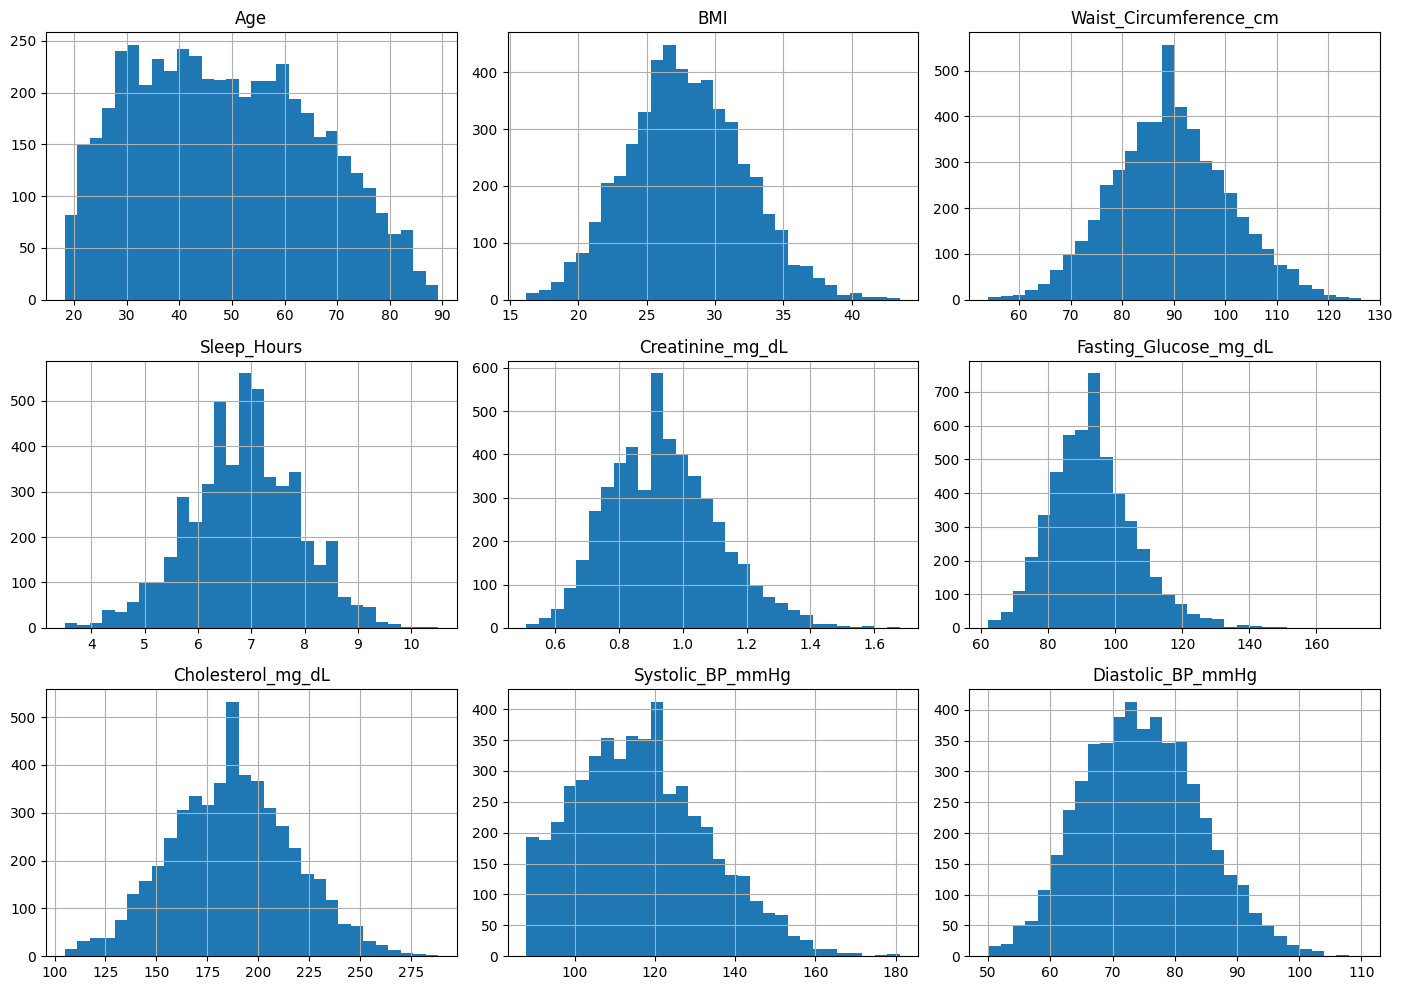

Age                       0.21
BMI                       0.17
Waist_Circumference_cm    0.10
Sleep_Hours              -0.08
Creatinine_mg_dL          0.43
Fasting_Glucose_mg_dL     0.65
Cholesterol_mg_dL         0.06
Systolic_BP_mmHg          0.48
Diastolic_BP_mmHg         0.20
dtype: float64


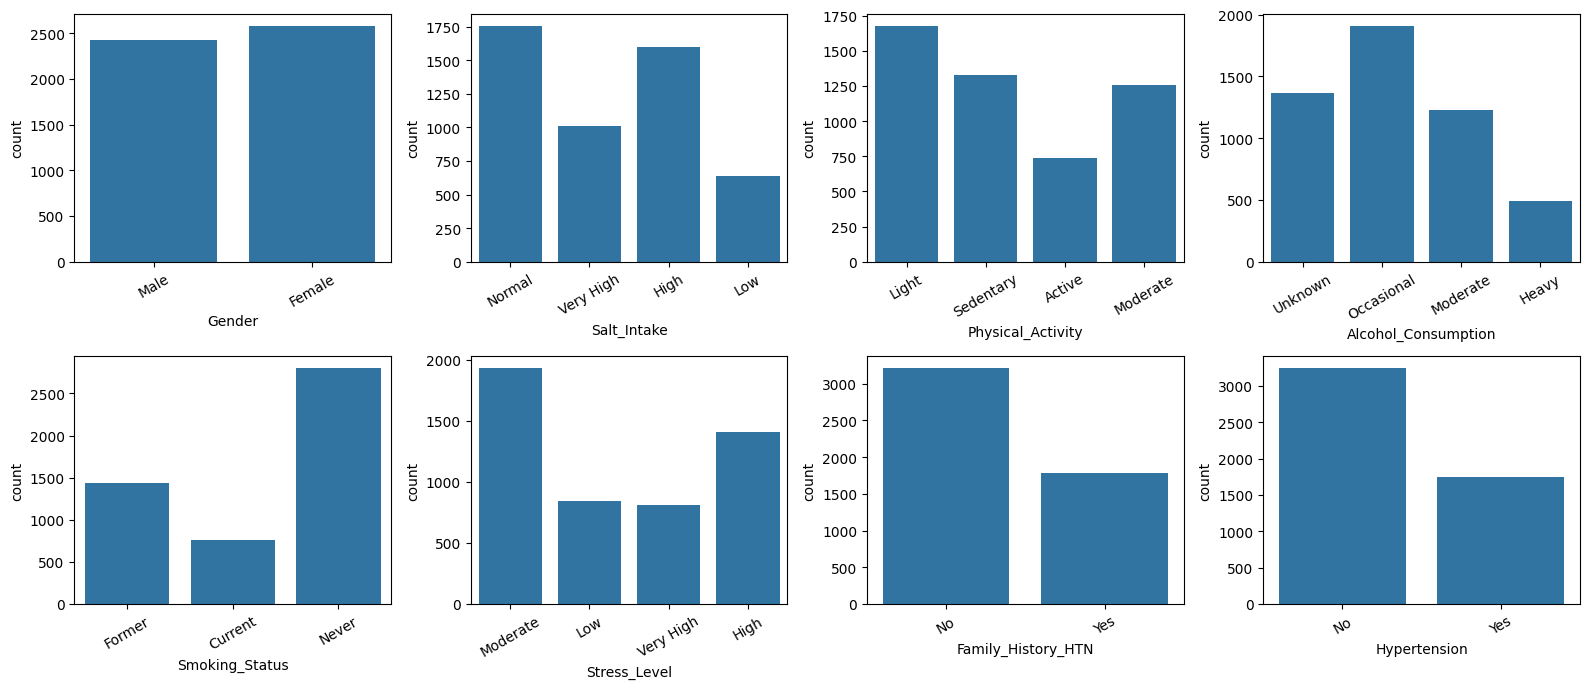

In [ ]:
df[num_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()
print(df[num_cols].skew().round(2))


cols = cat_cols + ["Hypertension"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

From my figures above obtained from my cleaned dataset of 5,000 rows, the first is a grid of histograms for the numeric variables and the other is a grid of bar charts for the categorical variables. The skew values are printed as text between them.

The skewness and the outliers are within the range e.g glucose of 173 is realistic for a diabetic patient in the UK as per the National Institute for Health and Care Excellence (under the section "Target blood glucose levels" Page 10), so I will keep it for further analysis on numeric columns using histograms + skewness and categorical columns using count plots

**ANALYSIS FOR THE HISTOGRAMS FOR THE NUMERIC VARIANCE**

**AGE**

Ages range from 18.2 to 89.2 years wide distribution with mean age of 48.6 years, SD age is 16.9 and median age of 47.4 years. The slight positive skewness (0.21) indicates a moderate tail towards the tail end of the ages, and a mean age of about 1.2 years higher than the median is consistent with this. The negative value of the excess kurtosis (-0.92) suggests that the distribution is flatter than a normal curve, meaning that patients are not clustered around a typical age, but are fairly evenly distributed across adulthood with a peak of 200-245 patients per age bar between age 28 and age 60. There is an under-representation in the youngest bar of 18-21 years, possibly due to the adult only cut-off, and a gradual decrease in frequency after age 60, with fewer than 200 patients aged 80 years and over. The age bands are fairly balanced with 714 patients from 18 to 29 years and 963 patients from 30 to 39 years. The broad age coverage also resulted in a strong association with hypertension, with 13% prevalence in the youngest group from 18-29 years and 63% in the oldest group from 70 years old and older. The study had good power for this relationship. With the almost symmetric shape indicating older people have higher risk of hypertension compared to younger peaple.

**BMI**

The BMI was normally distributed, with a range from 16.2 to 43.5 kg/m², the mean was 27.9 and SD was 4.3 and median was 27.7. The distribution is unimodal, with the highest frequencies around 25–27 of around 420–450 patients per bin. The skewness was slight (0.17) indicating a slightly longer tail towards higher BMI values, and excess kurtosis was near to zero (-0.12) indicating tails similar to a normal curve. By standard clinical categories, the cohort leans heavily toward elevated body weight. 43.9% of patients were overweight representing BMI 25 to 29.9; n = 2,195, 30.8% were obese n = 1,542, 24.5% were of normal weight n = 1,223, and only 0.8% were underweight n = 40. Twenty three repsenting 0.5% observations were outside the 1.5 x IQR fences (less than 16.0 or greater than 39.7) and these were mostly high values which were likely to be associated with severe obesity. Because of the steadily increasing prevalence of hypertension across all BMI categories (5.0% in the underweight patients, 21.3% in normal-weight patients, 34.0% in overweight, 45.8% in BMI 30-34.9, and 59.3% in BMI ≥35), BMI is a strong correlate of hypertension in this data set. BMI was only weakly positively correlated with age (r = 0.16) which implies that dataset give a lot of independent data. Hypertension prevalence rose steadily with BMI, from 5.0% in underweight patients to 59.3% in those with a BMI of 35 or above.

**WAIST CIRCUMFERENCE**

The 5,000 patients having a mean Waist circumference of 89.4 cm with a standard deviation of 11.2 cm were normally distributed with a range of 54.0 to 126.4 cm and a median 89.1. The skewness was very slight (0.10) and the excess kurtosis was very close to zero (-0.04), suggesting a symmetric, bell-shaped distribution with normal tails. A peculiarity is the high number of observations at the value 89.1 cm, the median, which is 171 representing 3.4% of all observations, all other values do not occur more than 26 times. The tallest histogram bar 87.8-90.2 cm, approximately 556 patients is explained by the pattern of missing values that I observed when doing the data cleaning, which is typical of imputing the median value when data is missing. Thirty three observations representing 0.7% were outside the lower or upper 1.5X IQR (lower 59.3 and upper 119.3 cm). Waist circumference differed by sex, averaging 93.7 cm (SD = 10.3) in males n = 2,419 and 85.4 cm (SD = 10.6) in females n = 2,581. 30% of the cohort n = 1,540 had central obesity (men >102 cm, women >88 cm) and 58% n = 2,905 had central obesity (men >94 cm, women >80 cm) using the IDF definitions. Prevalence of hypertension was consistently higher with progressive increases in waist circumference quartiles, 17.3% in the lowest quartile (≤81.8 cm), 30.1% in the highest (>96.8 cm), and was 46.8% in patients with central obesity compared to 29.8% in patients who did not have central obesity.

**SLEEP HOURS**

The patients' sleep duration was normally distributed with a range of 3.5 to 10.5 hours per night mean 6.85, SD 1.02, median 6.9. The skewness (-0.08) and excess kurtosis (0.08) were both near zero, suggesting a symmetric, bell-shaped distribution with normal tails and the highest frequencies were between approximately 6.3 and 7.3 hours. Like waist circumference, there is a striking peak at the median: 362 patients representing 7.2% reported 6.9 hours, nearly double the number of patients who reported 6.8 hours. There are 57 observations (1.1%) outside the 1.5 × IQR fences 4.25 hours below, 9.45 hours above. Based on my dataset's sleep categories, 55.4% of patients n = 2,772 are classified as short sleepers, 42.7% n = 2,135 as normal sleepers, and only 1.9% n = 93 as long sleepers; about 18.8% n = 941 slept fewer than 6 hours per night. Short sleepers represented 38.3% had the highest prevalence of hypertension, followed by normal sleepers at 31.3% and long sleepers at 21.5%. When sleep is grouped by hour, prevalence is 41.0% among those sleeping 5 hours or less and 43.4% among those sleeping 5 to 6 hours, declining to 35.2% at 6 to 7 hours, 31.9% at 7 to 8 hours, 29.8% at 8 to 9 hours, and 19.2% at more than 9 hours. Some weak negative correlations were observed between sleep duration and systolic blood pressure (r = -0.15), age (r = -0.11), and BMI (r = -0.10); however, the sleep duration was lower in the very-high-stress group at 6.43 hours than in the low-stress group at 7.22 hours, indicating that stress may be partially responsible for the relationship between short sleep and hypertension.

**CREATININE LEVEL**

The 5,000 patients creatinine level was unimodal and slightly right-skewed, with a range of 0.51 to 1.68 mg/dL with a mean of 0.94, SD 0.17 and median 0.93. Skewness was 0.43 and excess kurtosis 0.16 this is typical range of creatinine. As seen above, a peak at n = 242, 4.8% of the sample size, the same as the median, and almost twice as high as the next most common value of 0.95, n = 129. There were 39 observations 0.8% above the upper fence of 1.40 mg/dL, but no value below the lower fence. The average value of creatinine was significantly different between males n = 2,419, mean = 1.04 mg/dL, SD = 0.15 and females n = 2,581, mean = 0.85 mg/dL, SD = 0.13. In a total of 218 patients at 4.4%, the values exceeded the approximate upper limits of 1.3 mg/dL in men and 1.1 mg/dL in women (128 men and 90 women), and in 366 patients at 7.3%, the values were over 1.2 mg/dL.I found creatinine to be significantly higher in older patients, with a mean of 1.02 mg/dL for patients aged 60 or older, 0.94 mg/dL for patients aged 40 to 59 and 0.87 mg/dL for those aged 39 or lower. The prevalence of hypertension increased gradually across the creatinine quartiles, from 18.4% in the lowest group at 0.82 mg/dL, to 29.8%, 40.3%, and 53.6% in the highest group at 1.05 mg/dL. The group with creatinine >1.2 mg/dL had a prevalence of 56.8%, compared with 33.3% in the group with creatinine at or below >1.2 mg/dL. Moderate correlation rates were observed between creatinine and both systolic (r = 0.36) and diastolic (r = 0.30) blood pressure and weak correlation rates with BMI (r = 0.14). It is therefore important to understand that this association may be attributed to age or sex as these variables also affect creatinine and the risk for hypertension.

**FAST GLUCOSE**

The distribution of fasting glucose is unimodal, moderately right skewed, with a range of 62.1–173.4 mg/dL, mean of 93.3, SD of 12.5, and median of 92.2. The skewness is 0.65 and excess kurtosis 1.15. A similar peak at the median is seen for several other variables: 197 patients at 3.9% had 92.2 mg/dl. 1.9 % of observations at 94 were above the upper 1.5 × IQR fence of 123.8 mg/dL and none below the lower fence; these are likely to be values from those with undiagnosed or poorly controlled diabetes, but the highest value 173.4 mg/dL falls far from most of the distribution. Using standard clinical thresholds, 74.2% of patients n = 3,708 had normal fasting glucose of less than100 mg/dL, 24.2% of n = 1,212 were in the prediabetic range of 100 to 125 mg/dL, and 1.6% of n = 80 were in the diabetic range more than 126 mg/dL. 79 patients at 1.6% had values below 70 mg/dL. Glucose mean values increased with age. 89.1 mg/dL in patients younger than 39 years, 93.1 mg/dL in patients ages 40 to 59, and 98.1 mg/dL in patients age 60 or older (r = 0.31). the means were almost the same between males at 93.27 mg/dL and females at 93.25 mg/dL. The mean glucose level was slightly elevated in patients with a family history of hypertension at 95.1 mg/dL vs 92.2 mg/dL. The prevalence of hypertension significantly increased with glucose.The moderate correlation between glucose and systolic blood pressure (r = 0.36) and BMI (r = 0.36) and glucose and waist circumference (r = 0.32) indicated clustering of metabolic risk factors. The glucose/ hypertension relationship is likely to be mediated by part of the glucose/ age and glucose/ adiposity association.

**CHOLESTEROL LEVEL**

The distribution of total cholesterol for the 5000 patients is close to normal with a range of 105.0 to 288.3 mg/dL and mean = 187.2, SD = 30.1, median = 187.3. The skewness is close to zero (0.06), and so is excess kurtosis (-0.12), meaning that the distribution is symmetric and bell-shaped. Similar to several other variables, an increase at the median value is noted, 167 patients at 3.3% had a value of 187.3 mg/dL, while only a maximum of 13 is observed for any other value. There is 21 observations at 0.4% outside the 1.5 × IQR fences at -105.3 mg/dL to +268.0 mg/dL with nearly all of them falling above the upper fence +268.0 mg/dL. Using standard clinical thresholds, 67.5% of patients n = 3,374 had desirable cholesterol less than 200 mg/dL, at 28.4% n = 1,418 were borderline high representing 200 to 239 mg/dL, and at 4.2% n = 208 were high than 240 mg/dL. The mean level of cholesterol rose steadily with age (r = 0.33) 177.1 mg/dL in those aged 39 years or below, 186.0 mg/dL in those aged 40 to 59, 200.2 mg/dL in those aged 60 years or above and was slightly higher in females at 189.4 mg/dL than in males at 184.9 mg/dL. The prevalence of hypertension was generally increasing with the increasing quartiles of cholesterol ranging from 24.8% (≤166.3 mg/dL) to 32.0%, 36.4%, 47.2% (>207.0 mg/dL), respectively. The cardiometabolic profile was moderately associated with cholesterol r = 0.26, 0.24, 0.21, and 0.18, respectively, for systolic blood pressure, fasting glucose, BMI, and waist circumference.

**SYSTOLIC BLOOD PRESSURE**

Overall, across the 5,000 patients, a slight right skew of the systolic blood pressure with a range of 88 to 181 mmHg and mean = 116.8, SD = 16.4, median = 115. The skewness was 0.48 and excess kurtosis was -0.15, showing that the tails were not significantly longer toward the higher pressures, and that the most frequent values occurred very rarely in about 2.4% of patients. 22 observations representin 0.4% had values above the upper 1.5 x IQR fence 164 mmHg, with none below the lower fence. Using the dataset's systolic categories, 59.6% of patients n = 2,982 were normal less than 120 mmHg, 30.4% n = 1,518 were elevated 120 to 139 mmHg, and 10.0% n = 500 were higher than 140 mmHg, of whom 42 patients had readings of 160 mmHg or above. Systolic pressure increased significantly with age (r = 0.54) with an average of 107.4 mmHg in patients 39 years or less, 116.0 mmHg in patients 40-59 years, and 128.5 mmHg in patients 60 years or more, and was higher in males at 119.0 mmHg than females at 114.8 mmHg. It also correlated positively with WC (r = 0.39), FBG (r = 0.36), creatinine (r = 0.36), BMI (r = 0.34), and cholesterol (r = 0.26), and negatively with sleep duration (r = -0.15), with the correlation being strong with DP (r = 0.78). Patients with a hypertension diagnosis n = 1,750, 35.0% had a mean systolic pressure of 133.1 mmHg and SD = 12.5 compared with 108.1 mmHg and SD = 10.5 in those without. Notably, none of the patients without hypertension had a reading above 129 mmHg and all of the patients with a systolic blood pressure of 140 mmHg or more were classified as being hypertensive.


Limitation: Circularity is the primary concern with blood pressure (diastolic) because the data makes the connection between blood pressure and definition of hypertension, which makes this connection somewhat built into the data and is not independent. Stress, caffeine or the "white-coat" effect and treatment may all influence a single reading, which can also be normal despite the fact that the patient is hypertensive. There is a strong correlation between the two (r = 0.78), meaning that diastolic provides little additional information, and the tails are small – high (6.2%) and low (5.0%).

Next to investigate: The number of patients who are recorded as hypertensive by systolic readings only, diastolic readings only or both readings, and how many "Yes" patients have normal readings on both, which may be treated patients. Remove the two blood-pressure columns from each of the prediction models, and test if age, BMI, waist and salt predict diastolic pressure. Multiple or walking readouts would provide a more solid basis for making any conclusions.

**DIASTOLIC BLOOD PRESSURE**

The response variable diastolic blood pressure is unimodal and approximately normally distributed among the 5,000 patients with a range of 50 to 110 and mean = 74.3, SD = 9.5, median = 74 mmHg. There is little skewness (0.20) and excess kurtosis (-0.24), which represent a distribution that is almost symmetric and has slightly flatter tails than the Gaussian distribution, respectively. The most common value 72 mmHg was observed for only 4.2% of patients. There were 11 observations representing 0.2% beyond the upper fence of 102 mmHg (1.5 × IQR), no observations were below the lower fence. Using the dataset's diastolic categories, 70.7% of patients n = 3,533 were normal 80 mmHg, at 23.1% n = 1,155 were elevated representing 80 to 89 mmHg, and at 6.2% n = 312 were higher than 90 mmHg, including 24 patients with readings of 100 mmHg or above; 251 patients at 5.0% had values below 60 mmHg. The diastolic pressure increased with age (r = 0.34), and was higher in males at 76.3 mmHg than in females at 72.4 mmHg. It was strongly correlated with systolic pressure (r = 0.78) and moderately correlated with waist circumference (r = 0.34), creatinine (r = 0.30), fasting glucose (r = 0.28), and BMI (r = 0.26) with weaker associations with cholesterol (r = 0.18) and sleep duration (r = -0.11). Patients with hypertension n = 1,750, at 35.0% had a mean diastolic blood pressure of 84.0 mmHg and SD = 6.2 compared to 69.0 mmHg and SD = 6.3 in patients without hypertension, and the blood pressure readings gave a perfect classification of the patients. every patient with both blood pressure readings at or above 130 mmHg / 80 mmHg was classified as hypertensive n = 1,750, and no patient with blood pressure readings below both thresholds was classified as being without hypertension n = 3,250. However, 645 patients at 12.9% had a systolic reading less than 130 mmHg, and were all considered to be hypertensive by diastolic criteria only.

Circularity is the primary concern with blood pressure (diastolic) because the data makes the connection between blood pressure and definition of hypertension, which makes this connection somewhat built into the data and is not independent. Stress, caffeine or the "white-coat" effect and treatment may all influence a single reading, which can also be normal despite the fact that the patient is hypertensive. There is a strong correlation between the two (r = 0.78), meaning that diastolic provides little additional information, and the tails are small – high (6.2%) and low (5.0%).

Next to investigate: The number of patients who are recorded as hypertensive by systolic readings only, diastolic readings only or both readings, and how many "Yes" patients have normal readings on both, which may be treated patients. Remove the two blood-pressure columns from each of the prediction models, and test if age, BMI, waist and salt predict diastolic pressure. Multiple or walking readouts would provide a more solid basis for making any conclusions.

**ANALYSIS FOR THE BAR CHARTS FOR THE CATEGORICAL VARIABLE**

**GENDER**

Gender is almost evenly distributed with 2419 males at 48.4% and 2581 females at 51.6%. Males and females were well matched on age 48.4 vs 48.9 years, p = 0.30, BMI was at 27.8 vs 28.0 kg/m², p = 0.14, fasting glucose at 93.3 vs 93.2 mg/dL, p = 0.95, physical activity, salt intake, and family history of hypertension at 34.9% vs 36.3%, so the sex comparison is not confounded by these factors. Males did, however, have a markedly larger waist circumference at 93.7 vs 85.4 cm, p < 0.001, higher systolic at 119.0 vs 114.8 mmHg and diastolic at 76.3 vs 72.4 mmHg, pressure both p < 0.001, and slightly lower cholesterol 184.9 vs 189.4 mg/dL, p < 0.001. There were also some differences in lifestyle factors, with males being more likely than females to be current smokers at 18.5% vs 11.9% or former smokers at 31.9% vs 25.9%, and to heavy alcohol consumption 15.2% vs 4.8% or unknown alcohol status 31.1% vs 23.4%. The prevalence of hypertension was significantly higher in males at 43.4%, n = 1,049 than females at 27.2%, n = 701. The male excess was consistent across every age band, with prevalence of 19.8% vs 7.9% in those under 30, 30.7% vs 13.9% at ages 30 to 44, 49.9% vs 26.9% at ages 45 to 59, and 65.0% vs 51.8% at 60 and over, although the gap narrowed in the oldest group. These results indicate that gender is a significant correlate of hypertension in this sample and the higher frequency of hypertension among males may be due to differences in central adiposity, smoking and heavy drinking, and other blood pressure differences.


Limitations: The data is cross-sectional, so the 43.4% vs 27.2% gap shows an association between being male and having hypertension but cannot show why. Gender is also recorded only as Male or Female, with no information on hormonal status, which matters because blood pressure in women tends to rise after menopause and the gap narrows at older ages (65.0% vs 51.8% at 60+). This shows men and women were well matched on age, BMI and glucose, but men had larger waists (93.7 vs 85.4 cm), smoked more (18.5% vs 11.9% current) and drank heavily more often (15.2% vs 4.8%), so central obesity, smoking and alcohol could explain part of the gap. Alcohol is the shakiest of these, since 27% of its values were missing and coded as "Unknown", and that group is more common among men (31.1% vs 23.4%). Some of the difference could also come from sample selection or from differences in who gets screened or diagnosed, and men's higher creatinine is largely a physiological sex difference, not a risk signal. Finally, the chart-level rates carry no confidence intervals or adjustment for other variables.

What to investigate next: Run a logistic regression with gender alongside age, waist circumference, smoking, alcohol, salt intake and family history to see how much of the male excess remains once those are accounted for. Then check whether the gender gap changes with age or waist size, and whether risk factors act differently in each sex, for example whether heavy drinking or high salt is more damaging in men. Menopausal status and measured, not self-reported, lifestyle data would give a firmer basis for any conclusions.

**SALT INTAKE**

The bar chart displays the percentage of people with hypertension in each intake group, and this graph has a clear and consistent trend of increasing with salt consumption. Approximately 18% of the Low group individuals are hypertensive, 27% of the Normal group, 39% of the High group, and 54% of the Very High group. For each increment in salt consumption, there is an increment in the rate. The difference in likelihood of having hypertension between those in the highest quintile 54% and the lowest quintile 18% of intake is large and would not likely have occurred by chance. This is confirmed by the chi-square test, which indicates that the pattern is extremely unlikely to occur by chance if there were no link between salt consumption and hypertension. Salt is among the most powerful lifestyle factors in the analysis, second only to physical activity (49% sedentary vs 19% active). It is easily changeable, making it likely the most actionable finding in health education.

Limitation: The salt finding has a number of drawbacks. However, the data is observational and cross-sectional, and cannot be used to determine whether people who consume high amounts of salt are more likely to have hypertension, or if hypertension is a cause of eating lots of salt. People also report their salt intake as being Low to Very High, suggesting it is not an exact measurement (like urinary sodium) and, thus, may also be subject to recall or social-desirability bias, and the salt intake ranges between the categories are not specified. There is a possibility of confounding: older, heavier, less active, and/or male participants might have increased blood pressure, and more salt intake, so some of the gradient might be due to such factors, especially since age was the strongest predictor in the analysis. There's also a possibility of reverse causality, since those who already have hypertension may have been advised to reduce their sodium intake and this could make it harder to understand the actual relationship. The most common category was used to fill in the 61 missing values, which somewhat reduces the impact of real differences; and the chart presents raw rates only and does not include confidence intervals or adjust for other factors.

What to investigate next: It is now necessary to see if salt still affects the plants after other factors have been taken into consideration. That is, using logistic regression with salt intake in addition to age, BMI, gender, physical activity, and family history of hypertension, comparing salt-related odds ratios before and after adjustment. Also looking for pattern within age bands and BMI groups, and for any interactions, such as high salt being particularly hazardous for older patients or obese patients, would be helpful. The trend that's consistent with the dose-response relationship further supports the recommendation for reducing salt intake, and the analysis could be repeated using the measured sodium variable to increase the likelihood of confirming the trend. Imputation sensitivity tests, including the removal of the 61 missing records, would reveal whether the outcome is sensitive to the imputation of the missing records.

**PHYSICAL ACTIVITY**

The bar chart represents the proportion of people in each physical activity group who have hypertension and the proportion decreases regularly as activity increases. Around 49% of sedentary people were hypertensive, whereas 38% of the Light group, 25% of the Moderate group and 19% of the Active group were. However, sedentary individuals have an estimated 2.6-fold greater risk of hypertension than active individuals, and for every additional step of activity, the risk of hypertension decreases, indicating a dose-response relationship rather than a binary distinction between active and inactive. Physical activity is, along with salt intake, one of the two strongest lifestyle factors in the analysis and is modifiable, which makes it a good target for prevention and health education.

Limitations: Observational and cross-sectional, association but not cause and effect that inactivity leads to hypertension. Activity is likely to be self-reported in general terms and without specific thresholds and, therefore, open to recall and social-desirability bias. There is likely to be confounding: age and BMI/waist size may both contribute to inactivity and increased blood pressure, thus part of this gradient may be due to these factors. The reverse direction of the relation is also a possibility because people with hypertension or related conditions may become less active. Rates are displayed only; no confidence intervals or adjustment for other rates.

What investigate next: Run a logistic regression that includes physical activity, as well as age, BMI, gender, salt intake and family history to see if the gradient persists after adjusting for these factors. Afterwards, look for any trend in age and BMI bands, and test if there is an interaction – is there a difference in activity and salt levels (is high salt less harmful in active people)? Any recommendations would be more solid if they were based on measured activity data, e.g. steps or exercise minutes.

**ALCOHOL CONSUMPTION**

The bar chart displays the proportion of people in each alcohol consumption group who had hypertension, which increases with the level of alcohol consumption. Approximately 29% of the Unknown group have hypertension, while approximately 32% of the Occasional drinkers, 40% of the Moderate drinkers and 50% of the Heavy drinkers have hypertension. There is therefore approximately 1.5 times the risk of hypertension for heavy drinkers compared to occasional drinkers, and the transition from occasional to moderate to heavy drinking is consistent, indicating a dose-response relationship. The chi-square test confirms this and the differences are highly improbable to be due to chance. The effect is real, but less than for salt intake or physical activity, which is consistent with the finding that alcohol is a weaker factor.

Limitaion: The largest fault is that approximately 27% of alcohol values were not entered, but were instead coded as "Unknown", which is not a true drinking category. The low rate (29%) must not be interpreted as indicating that there is a relationship between abstainer and better health; rather, it could reflect that people who fail to report drinking are light drinkers and/or those who refused to answer the drinking question. Alcohol is also self-reported in general terms and without a specific cut-off, meaning that the amount may be underestimated, particularly among heavy drinkers. There can be confounding: heavy drinkers in these data are more likely to be male and more likely to be smokers and men were far more likely to have hypertension, so part of the gradient may be due to gender and smoking. The data used is cross-sectional and cannot demonstrate that drinking preceded hypertension and the chart presents unadjusted and non-interval rates.

What to investigate next: Conduct logistic regression using alcohol in addition to gender, age, BMI, smoking and salt intake to determine if the heavy drinking effect remains after adjusting for these other factors and compare within gender. If only Complete cases were analysed, then the impact of missing data would be highlighted in the Unknown group. If it could be quantified (units per week, for example), that would provide a more solid foundation on which to make any conclusions.

**SMOKING STATUS**

The bar chart demonstrates the hypertension rate for each smoking status group, which is not a linear "more smoking, more hypertension" relationship. Current smokers have about 35% with hypertension, former smokers have about 43% and people who have never smoked have about 31% with hypertension. Former smokers show the highest rate at 1.4 times higher than never-smokers, followed by current smokers. The difference is not due to chance but is much smaller than the difference between salt intake and physical activity, which is consistent with the small effect size found for smoking. The most surprising part of the chart is the result for former smokers; this indicates that the smoking status shown on this chart is related to other factors, and not necessarily to the harm associated with smoking.

Limitation: The data is cross-sectional, which means that it can't determine whether smoking caused hypertension or whether hypertension caused smoking. This high rate among former smokers is easily explained by other factors. The age is one of the strongest predictors of hypertension in this analysis and former smokers were older, so the result may be due to age. In addition, people are likely to drop off after a health scare or diagnosis, and some may have become heavier following quitting. The categories provide no information on how much, how long or how recently someone has smoked, and smoking status is likely to be self-reported, leading to under-reporting. Confounding by gender and alcohol may exist in this data, as smokers tend to be heavier drinkers and male. The chart shows raw rates with no confidence intervals or adjustment.

What to investigate next: Perform a logistic regression including smoking status, age, gender, BMI, alcohol and salt intake to assess whether the excess due to smoking remains after controlling for these other potential factors and compare the mean ages of the 3 smoking groups to test the age explanation directly. It would also be useful to make the comparison within each age band. Some information about pack-years and time since quitting would provide a more solid bases for any conclusions.

**STRESS LEVEL**

The Chart displays the rate of hypertension among each stress level group. The higher the reported stress level, the higher the rate of hypertension, but the increase is not steep and consistent. Approximately 30% of individuals in the Low stress group are also diagnosed as having hypertension, while approximately 32% of those in the Moderate stress group, 36% of those in the High stress group and 44% of those in the Very High stress group have hypertension. The majority of the disparity is due to the top of the scale – the transition from Low to Moderate is small, whereas Very High stress is approximately 1.5 times the Low stress. The result of the chi-square test is strong evidence that the pattern is not due to chance, and the association is much less powerful than for salt intake or physical activity, which is consistent with the finding that stress has only a small effect size. This is therefore a partial correlation with stress as a secondary variable.

Limitation: Cross-sectional cannot determine if stress preceded hypertension. Stress is very likely a self-reported category with no validated scale, and individuals might rate their level of stress differently, and it is a subjective measure at one moment in time. Reverse causality is possible as life with the diagnosis or treatment could increase stress. There is also a potential for confounding: stress is often associated with poor sleep habits, high alcohol consumption, smoking, lack of activity, and high salt intake -- any of these might be responsible. The 91 missing stress values were replaced with the most frequent category which somewhat reduces the effective difference. Raw rates (no confidence interval or adjustment).

What to investigate next: Run logistic regression with stress as well as age, BMI, gender, alcohol, smoking, physical activity, excess salt intake to determine if the Very High excess still exists after these adjustments. Examine if stress is associated with hours of sleep, as the notebook revealed, that the hypertensive patients slept somewhat less. Validated stress score and repeated measurements over time would provide increased credibility for any conclusions.

**FAMILY HISTORY**

The bar chart indicates that there are two groups (with and without family history of hypertension) and that the group with the family history is more affected. The rate is approximately 1.5 times higher, as about 44% of those with a family history suffer from hypertension, whereas approximately 30% of those without suffer from hypertension. Due to being a two-group comparison, the difference is readily discernable, approximately 14 percentage points represents the difference between the two groups. The chi-square test shows the difference is very unlikely to be chance. The association is significant but not as close as with salt intake and physical activity. Family history is also not modifiable - again the primary role of family history is to identify those who may benefit from earlier screening rather than shift behaviours.

Limitation: Data is cross sectional and family history is likely to be reported as a single dichotomy and depends on what people know and remember about relatives. Some may not know that a relative is diagnosed, and thus misclassify as "No," and make it unclear the difference. The variable also fails to indicate which relative it was, how closely related they were and when the relative got hypertension, which alter the meaning. Family history combines the effect of common genes with common environment e.g. family diet, salt intake, physical activity. So it isn't just the genetic risk. A recall bias is that individual with hypertension might be more likely to inquire about and report family history. The age effect can be confounded, older people may have more relatives with a diagnosis. This chart presents unadjusted rates without confidence intervals.

What to investigate next: Fit a logistic regression model including family history and other risk factors such as age, BMI, gender, salt intake and physical activity, to determine if the excess is still observed after controlling these factors. Next, try to determine if family history modifies the risk of lifestyle or other factors, such as high salt or lack of activity for those with family history (which would provide guidance for targeted prevention). If more detail about which relatives are involved and at what age, this would provide a better basis for making any conclusions.

**HYPERTENSION**

The bar chart for hypertension is a count plot, so it shows how many patients fall into each outcome group, not risk. There are approximately 3,250 at 65% of the 5,000 patients who are not hypertensive, and 1,750 at 35% of the 5,000 patients who are hypertensive, about 1.9 non-hypertensive for every hypertensive patient. So, the results are reasonably skewed - "Yes" is a distinct minority but not small enough that it can't be compared to the larger group of "No's". This is important for modelling as the model can be 65% correct if it always predicts "No". Therefore balanced class weights have been used and models are evaluated on recall and AUC rather than accuracy. The 35% prevalence is much higher than that of the general adult population, indicating that this is a clinical or specially selected sample instead of a random cross-section of adults.

Limitation: There are no counts of which factors are associated with hypertension. This is based on charts of rates by group. Results may not be representative of the general population, as it is likely that the prevalence of the 35% is related to the way the data set was created (such as a clinic sample or a synthetic data set). Readings from the blood pressure cuff are also strongly dependent on outcomes and it would be circular to predict hypertension just from systolic or diastolic pressure. There is no indication if this is a measured, a diagnosed or a labelled population of people with hypertension, so each would have defined it as a group of different people. Depending on the definition, a patient who has undergone treatment with a controlled pressure can be designated as "Yes" or "No," potentially making the groups somewhat confusing. The data is indicative only, and does not provide a picture of who becomes hypertensive later in life.

What to investigate next: Check the definition of outcome and if it matches the blood pressure which are considered to be high in the notebook (140/90), the number of "Yes" patients with normal blood pressure may be treated cases. The classes are imbalanced so continue to use recall, precision and AUC, and may wish to consider using stratified train-test splits to preserve the 35% share. If possible, compare this prevalence with national data to make a judgment on the representativeness of the sample.

Group sizes decide how reliable later comparisons are. The smallest groups (heavy alcohol with 491, current smokers with 755, low salt with 635) are still large enough for solid percentages. The Hypertension panel explains a modelling choice. Because a model could get 65% accuracy by always saying “No”, I used class_weight balanced and looked at recall and AUC instead of accuracy alone. These are counts and not risks. A tall bar here only means “many patients are in this group”. It does not say whether the group has more hypertension. That comes in Step 2, where you plot the hypertension rate within each group.

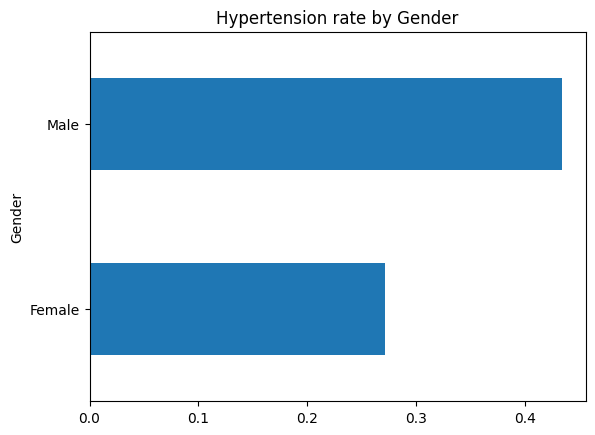

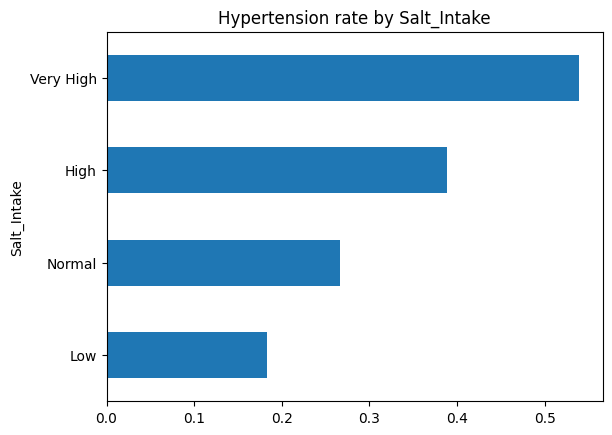

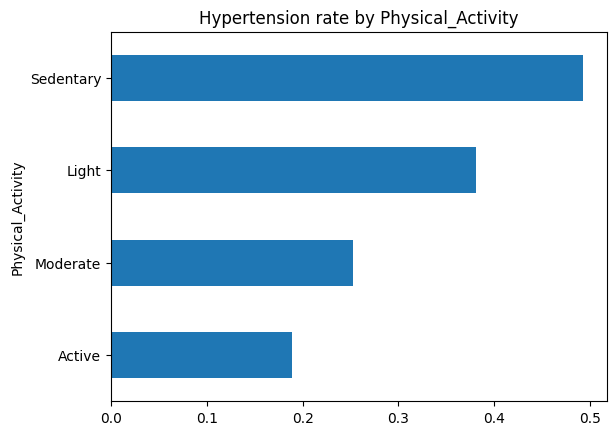

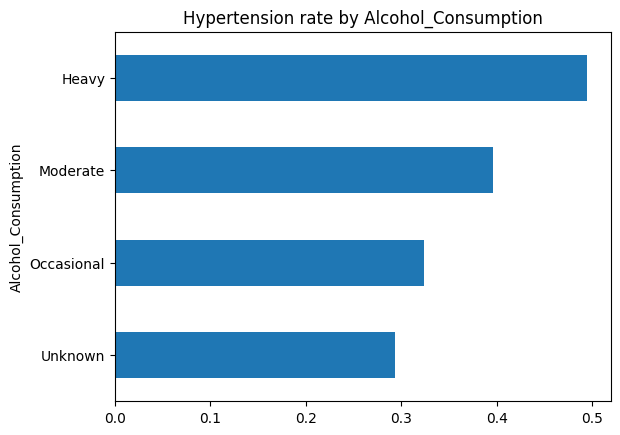

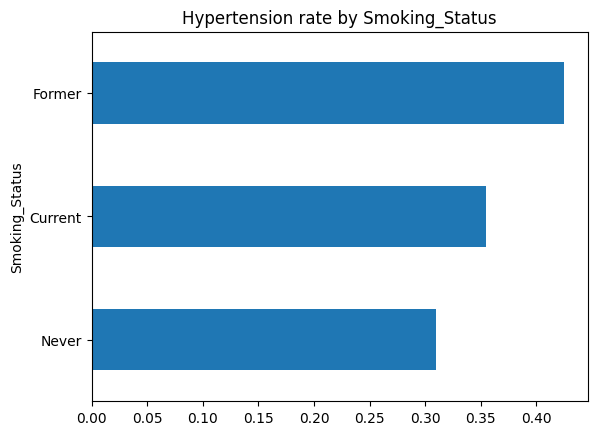

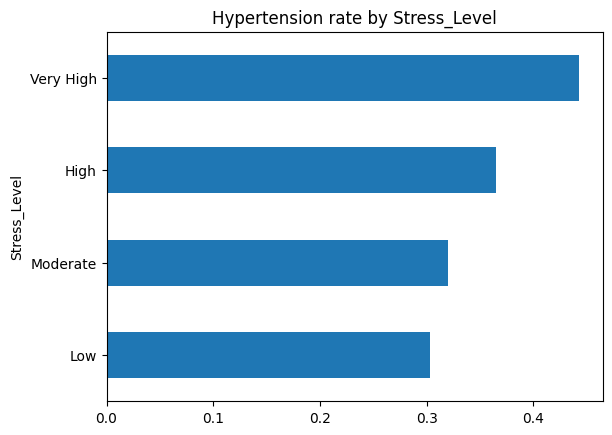

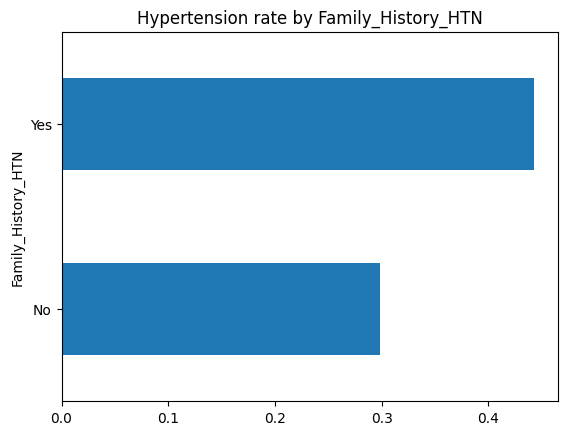

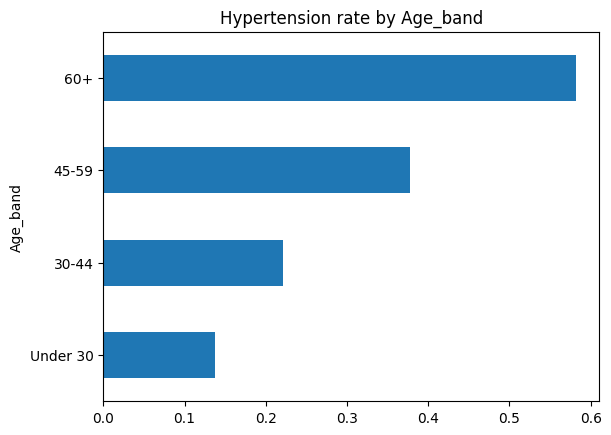

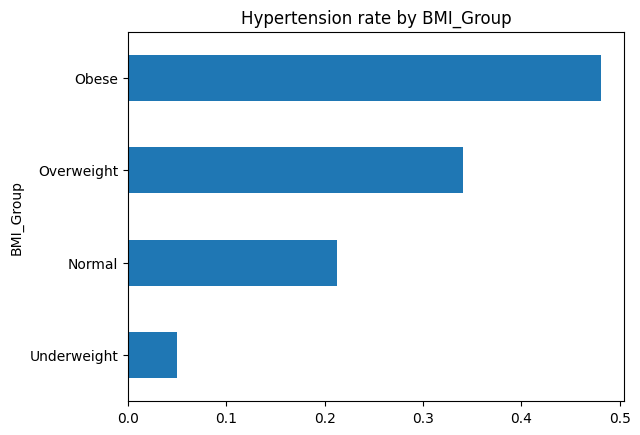

In [50]:
for c in cat_cols + ["Age_band","BMI_Group"]:
    rate = df.groupby(c)["HTN"].mean().sort_values()
    rate.plot(kind="barh", title=f"Hypertension rate by {c}"); plt.show()

This is the core of the analysis. It answers “which factors go with hypertension?”

Categorical factors (hypertension rate per group)

Age band: 14% under 30, rising to 58% at 60+ BMI group: 21% normal, 48% obese Physical activity: 49% for sedentary vs 19% for active Salt intake: 18% for low vs 54% for very high Gender: 43% for males vs 27% for females Family history: 44% for yes vs 30% for no